In [1]:
!pip install opencv-python
!pip install tensorflow
!pip install lime scikit-image

In [6]:
import pandas as pd              # Data manipulation and analysis
import numpy as np               # Numerical computations and array handling
import matplotlib.pyplot as plt  # Basic plotting and visualization
import seaborn as sns            # Enhanced statistical visualizations
import os                        # Filesystem operations
import cv2                       # OpenCV for image processing
from PIL import Image            # Image handling and manipulation
from itertools import chain

In [7]:
from sklearn.utils.class_weight import compute_class_weight  # Balancing class weights
from sklearn.metrics import (                                # Model evaluation metrics
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)
from sklearn.model_selection import train_test_split

In [8]:
from tensorflow.keras.models import load_model, Model, Sequential  # Model creation and loading
from tensorflow.keras import layers, regularizers, Model
from tensorflow.keras.optimizers import Adamax, SGD               # Optimization algorithms
from tensorflow.keras.regularizers import l2                      # Regularization for preventing overfitting
from tensorflow.keras.utils import to_categorical, plot_model     # Data preprocessing and model visualization
from tensorflow.keras.callbacks import (                          # Training callbacks
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from tensorflow.keras.preprocessing.image import img_to_array

In [9]:
from tensorflow.keras.preprocessing import image_dataset_from_directory  # Dataset loading from directories
from tensorflow.keras.preprocessing.image import ImageDataGenerator     # Real-time data augmentation

In [10]:
from tensorflow.keras.applications import (                      # Classic pretrained CNN architectures
    VGG16, EfficientNetB0, InceptionV3, MobileNetV2, DenseNet121
)
from tensorflow.keras.applications.efficientnet import EfficientNetB0  # EfficientNet model

In [11]:
import warnings
warnings.filterwarnings('ignore')

In [12]:
plt.style.use('seaborn-v0_8-whitegrid')  # Clean, professional aesthetic
sns.set_palette("deep")  # Subtle, professional color scheme

In [13]:
H, W = 224, 224
IMG_SIZE = (H, W)                      # Standard input size for pretrained models
IMG_SHAPE = (H, W, 3)
BATCH_SIZE = 32                       # Number of samples per gradient update
EPOCHS = 30                          # Maximum training iterations
LEARNING_RATE = 0.0001                 # Initial learning rate for optimizers
CLASS_NAMES = ['NORMAL', 'PNEUMONIA']  # Example class labels pneumonia
CLASS_COUNT = len(CLASS_NAMES)

In [14]:
import os
import pandas as pd

# Define the base directory where your data is stored (adjust this path)
base_dir = "/kaggle/input/chest-xray-pneumonia/chest_xray"  # e.g., "C:/pneumonia_project/data"

# List of dataset splits
splits = ["test", "train", "val"]
labels = ["NORMAL", "PNEUMONIA"]

# Initialize lists to store file paths and labels
file_paths = []
file_labels = []

# Loop through each split (train, valid, test)
for split in splits:
    split_dir = os.path.join(base_dir, split)
    # Loop through each label (normal, pneumonia)
    for label in labels:
        label_dir = os.path.join(split_dir, label)

        # Check if the directory exists
        if os.path.exists(label_dir):
            # Get all files in the label directory
            for file_name in os.listdir(label_dir):
                # Ensure it's a file (not a directory)
                if os.path.isfile(os.path.join(label_dir, file_name)):
                    # Add the full file path and corresponding label
                    file_paths.append(os.path.join(label_dir, file_name))
                    file_labels.append(label)

# Create a DataFrame with 'name' and 'label' columns
df = pd.DataFrame({
    "name": file_paths,
    "label": file_labels
})

# Optional: Save to a CSV file
df.to_csv("pneumonia_dataset.csv", index=False)
print("DataFrame saved as 'pneumonia_dataset.csv'")

DataFrame saved as 'pneumonia_dataset.csv'


In [15]:
df.head()

,name,label
0,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL
1,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL
2,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL
3,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL
4,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL


In [16]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Assuming your DataFrame is already created (e.g., from the previous step)
# If not, load it from the CSV:
# df = pd.read_csv("pneumonia_dataset.csv")

# Shuffle the DataFrame
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# First split: 70% train, 30% remaining
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,  # 30% for valid + test
    stratify=df["label"],  # Ensure label proportions are maintained
    random_state=42
)

# Second split: 20% valid, 10% test (from the original data)
# Since temp_df is 30%, we split it as 2/3 (20%) and 1/3 (10%) of original
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.333,  # 10/30 = 1/3 for test
    stratify=temp_df["label"],
    random_state=42
)

# Verify the sizes
print(f"Train set: {len(train_df)} samples ({len(train_df)/len(df)*100:.1f}%)")
print(f"Validation set: {len(valid_df)} samples ({len(valid_df)/len(df)*100:.1f}%)")
print(f"Test set: {len(test_df)} samples ({len(test_df)/len(df)*100:.1f}%)")
print(f"Total: {len(train_df) + len(valid_df) + len(test_df)} samples")


# Optional: Save the splits to CSV files
train_df.to_csv("train_split.csv", index=False)
valid_df.to_csv("valid_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)
print("\nSplits saved as 'train_split.csv', 'valid_split.csv', and 'test_split.csv'")

Train set: 4099 samples (70.0%)
Validation set: 1171 samples (20.0%)
Test set: 586 samples (10.0%)
Total: 5856 samples

Splits saved as 'train_split.csv', 'valid_split.csv', and 'test_split.csv'


In [17]:
%matplotlib inline


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_data_distribution(df, train_df, valid_df, test_df):
    """Vẽ biểu đồ phân phối dữ liệu đẹp hơn"""
    plt.figure(figsize=(18, 12), facecolor='white')

    # 1. Pie Chart: Dataset Split
    plt.subplot(2, 2, 1)
    sizes = [len(train_df), len(valid_df), len(test_df)]
    labels = ['Training Set', 'Validation Set', 'Test Set']
    colors = ['#66b3ff', '#99ff99', '#ffcc99']
    explode = (0.05, 0.05, 0.05)

    patches, texts, autotexts = plt.pie(sizes, labels=labels, colors=colors,
                                       autopct=lambda pct: f'{pct:.1f}%\n({int(pct/100.*sum(sizes))})',
                                       startangle=90, explode=explode,
                                       textprops={'fontsize': 12},
                                       wedgeprops={'edgecolor': 'white', 'linewidth': 1, 'alpha': 0.7})

    plt.setp(autotexts, size=12, weight="bold")
    plt.title('Dataset Split', fontsize=14, fontweight='bold', pad=20)

    # 2. Bar Plot: Overall Label Distribution
    plt.subplot(2, 2, 2)
    ax2 = sns.countplot(x="label", data=df, palette="Set2", edgecolor='black', linewidth=0.5)

    for p in ax2.patches:
        height = p.get_height()
        ax2.text(p.get_x() + p.get_width()/2., height + 3,
                f'{int(height)}\n({height/len(df)*100:.1f}%)',
                ha='center', va='bottom', fontsize=11)

    plt.title("Overall Label Distribution", fontsize=14, fontweight='bold', pad=10)
    plt.xlabel("Class", fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # 3. Pie Chart: Label Proportion
    plt.subplot(2, 2, 3)
    value_counts = df["label"].value_counts(normalize=True)
    value_counts.plot(kind="pie", autopct="%1.1f%%",
                     colors=['#ff9999','#66b3ff'],
                     textprops={'fontsize': 12},
                     wedgeprops={'edgecolor': 'white', 'linewidth': 1, 'alpha': 0.7})
    plt.title("Label Proportion", fontsize=14, fontweight='bold', pad=10)
    plt.ylabel("")

    # 4. Grouped Bar Plot: Label Distribution by Split
    plt.subplot(2, 2, 4)
    combined_df = pd.concat([
        train_df.assign(split="Train"),
        valid_df.assign(split="Validation"),
        test_df.assign(split="Test")
    ])

    ax = sns.countplot(x="label", hue="split", data=combined_df,
                      palette="pastel", edgecolor='black', linewidth=0.5)

    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.text(p.get_x() + p.get_width()/2., height + 2,
                   f'{int(height)}', ha='center', va='bottom', fontsize=10)

    plt.title("Label Distribution by Split", fontsize=14, fontweight='bold', pad=10)
    plt.xlabel("Class", fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.legend(title="Dataset Split", title_fontsize=12, fontsize=10,
              bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Adjust layout
    plt.tight_layout(pad=3.0)
    plt.suptitle("Dataset and Label Distribution Analysis", fontsize=16, fontweight='bold', y=1.02)

    plt.show()

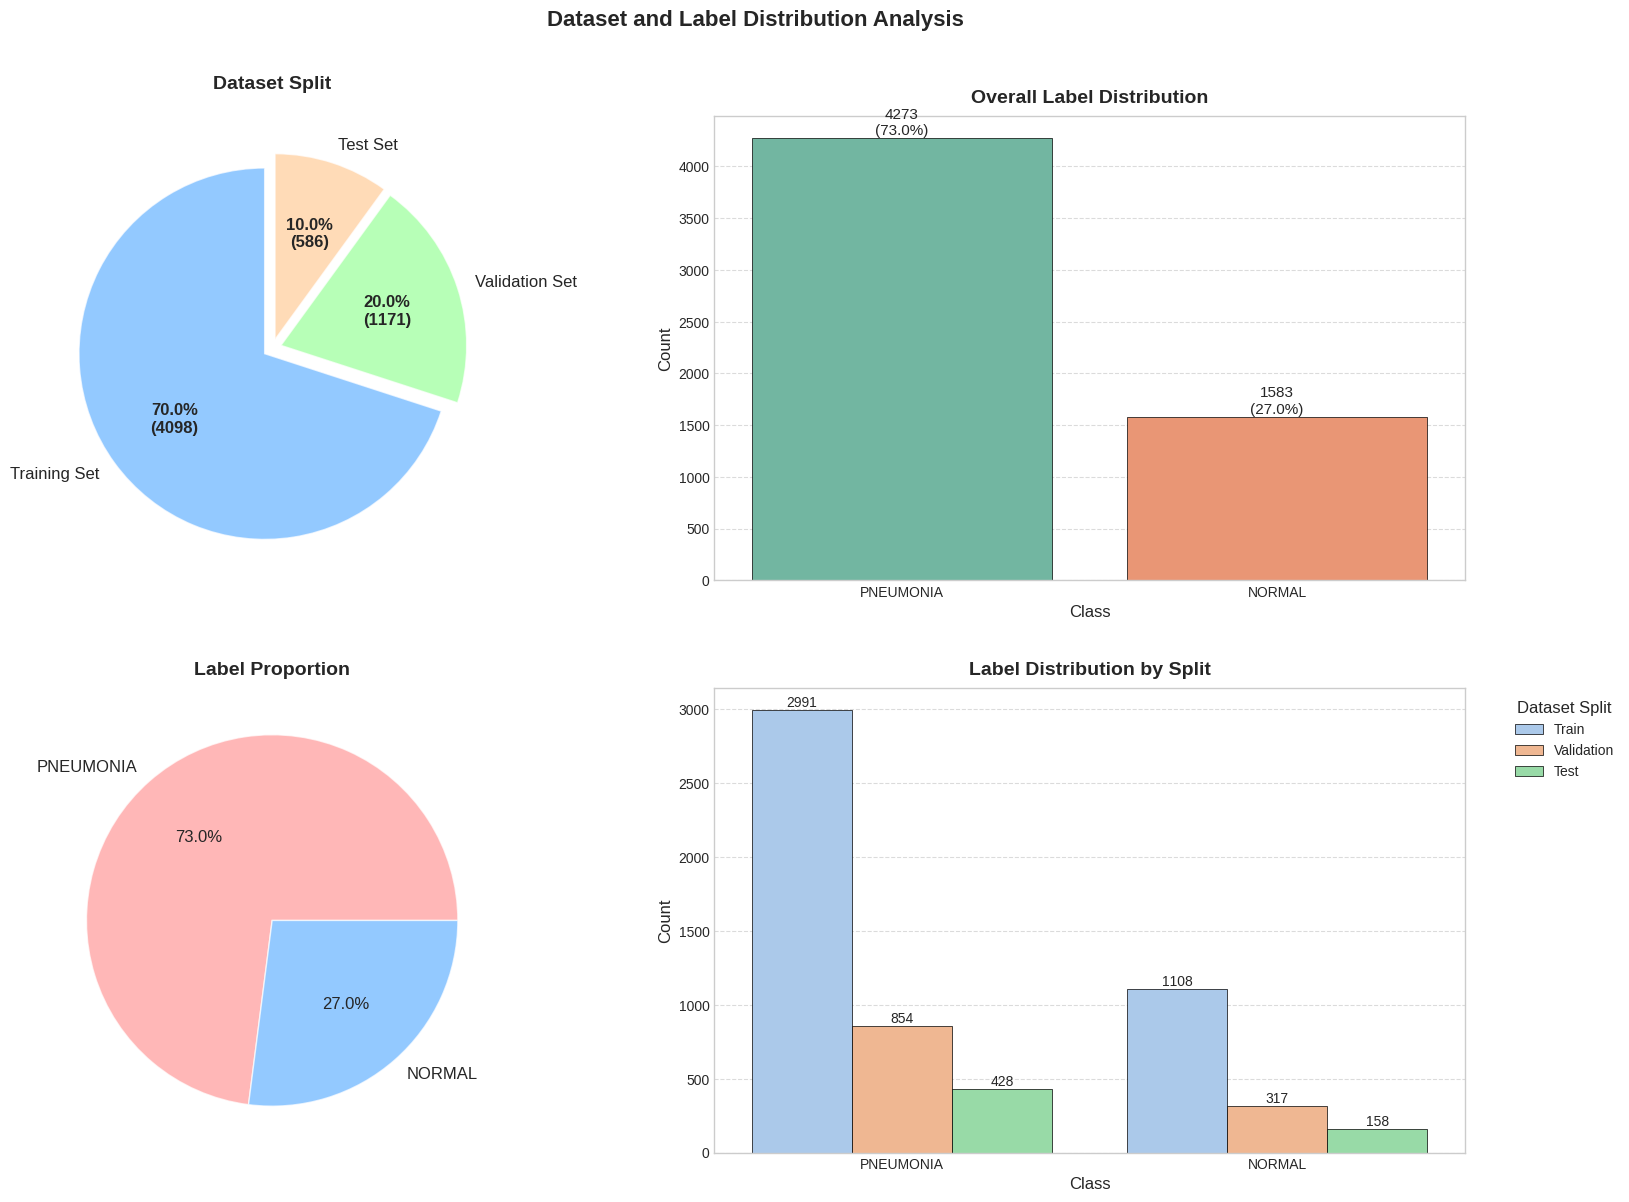

In [19]:
plot_data_distribution(df, train_df, valid_df, test_df)


In [20]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

# Training generator với augmentation + preprocessing
tr_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

# Validation/Test generator chỉ preprocessing
ts_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = tr_gen.flow_from_dataframe(
    train_df, x_col='name', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=True, batch_size=BATCH_SIZE
)
valid_gen = ts_gen.flow_from_dataframe(
    valid_df, x_col='name', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=True, batch_size=BATCH_SIZE
)
test_gen = ts_gen.flow_from_dataframe(
    test_df, x_col='name', y_col='label',
    target_size=IMG_SIZE, class_mode='categorical',
    color_mode='rgb', shuffle=False, batch_size=BATCH_SIZE
)


Found 4099 validated image filenames belonging to 2 classes.
Found 1171 validated image filenames belonging to 2 classes.
Found 586 validated image filenames belonging to 2 classes.


In [21]:
# Get a single sample
sample_row = df[df["label"] == label].iloc[0]
img_path = sample_row["name"]

# Before generator: Load raw image
raw_img = Image.open(img_path)
if raw_img.mode != 'RGB':
    raw_img = raw_img.convert('RGB')
raw_img = raw_img.resize(IMG_SIZE, Image.Resampling.LANCZOS)  # Match generator size
raw_array = np.array(raw_img)
print(f"Before Generator (Raw Pixels, Shape: {raw_array.shape}):")
print(raw_array[0, :5, :])  # Print first row, first 5 pixels, all channels

Before Generator (Raw Pixels, Shape: (224, 224, 3)):
[[112 112 112]
 [115 115 115]
 [114 114 114]
 [121 121 121]
 [118 118 118]]


In [22]:
image_batch, label_batch = next(train_gen)

# Print pixel values after generator
print(f"After Generator (Processed Pixels, Shape: {image_batch.shape}):")
print(image_batch[0, 0, :5])  # First image, first 5 rows, all columns, all channels

After Generator (Processed Pixels, Shape: (32, 224, 224, 3)):
[[101.58822 101.58822 101.58822]
 [101.49605 101.49605 101.49605]
 [101.40388 101.40388 101.40388]
 [101.31171 101.31171 101.31171]
 [101.21954 101.21954 101.21954]]


In [23]:
def plot_sample_images(df, label, num_samples=3, fixed_size=(224, 224)):
    # Filter by label
    label_df = df[df["label"] == label]

    if len(label_df) == 0:
        print(f"No images found for label '{label}'")
        return

    # Sample images
    samples = label_df.sample(min(num_samples, len(label_df)))

    # Set up figure with dark background
    plt.figure(figsize=(15, 5), facecolor='white')

    # Plot each image
    for i, (idx, row) in enumerate(samples.iterrows()):
        img = Image.open(row["name"])
        if img.mode != 'RGB':
            img = img.convert('RGB')
        img = img.resize(fixed_size, Image.Resampling.LANCZOS)

        plt.subplot(1, num_samples, i + 1)
        plt.imshow(img)
        plt.title(f"{label} #{i + 1}\nSize: {img.size}", fontsize=12)
        plt.axis("off")

    plt.suptitle(f"Sample {label} Images", fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()


Normal Samples:


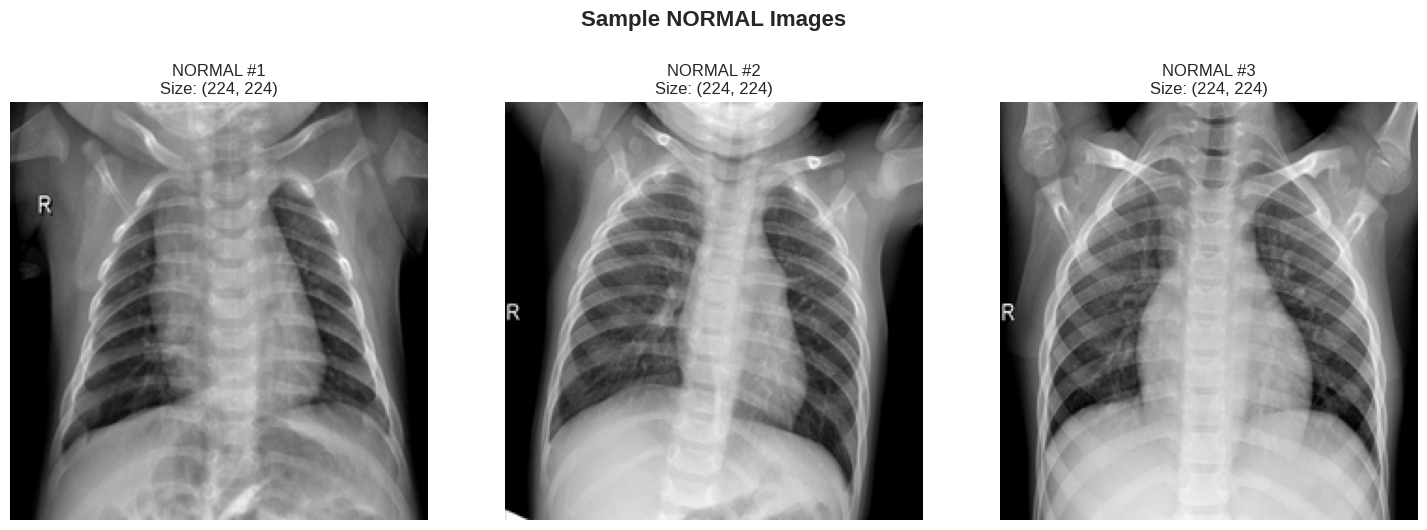


Pneumonia Samples:


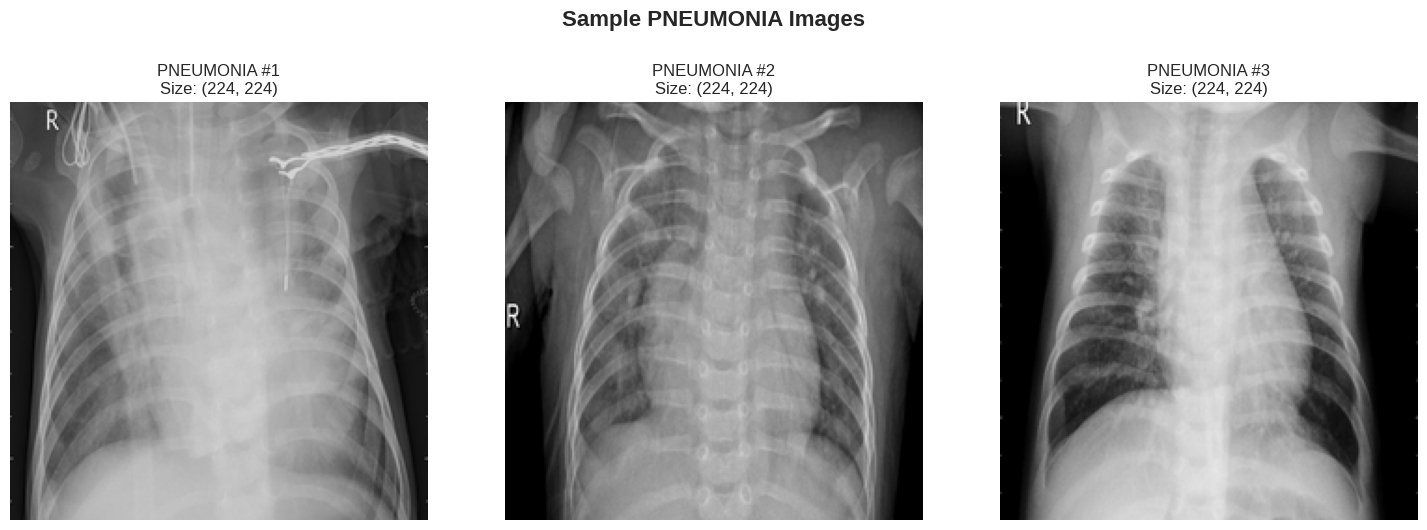

In [24]:
print("\nNormal Samples:")
plot_sample_images(train_df, "NORMAL")

print("\nPneumonia Samples:")
plot_sample_images(train_df, "PNEUMONIA")

In [25]:
# Define callbacks
callbacks = [
    ModelCheckpoint(filepath='/kaggle/working/best_model_V2.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1,mode='max'),

]

In [26]:

classes = list(train_gen.class_indices.keys())
class_indices = train_gen.class_indices


y_numeric = train_df['label'].map(class_indices)


class_weights = compute_class_weight(class_weight='balanced', classes=np.array(range(len(classes))), y=y_numeric)
class_weight_dict_mapped = dict(zip(class_indices.values(), class_weights))
class_weight_dict_mapped[0] *= 1.5  # Increase by 20%

In [27]:
def plot_training_history(history, figsize=(20, 8)):
    tr_acc = history.history['accuracy']
    tr_loss = history.history['loss']
    val_acc = history.history['val_accuracy']
    val_loss = history.history['val_loss']

    index_loss = np.argmin(val_loss)
    val_lowest = val_loss[index_loss]
    index_acc = np.argmax(val_acc)
    acc_highest = val_acc[index_acc]

    Epochs = [i+1 for i in range(len(tr_acc))]

    # Tạo figure với background màu trắng
    plt.figure(figsize=figsize, facecolor='white')

    # Subplot 1: Training and Validation Loss
    plt.subplot(1, 2, 1)
    plt.plot(Epochs, tr_loss, 'r', label='Training loss', linewidth=2)
    plt.plot(Epochs, val_loss, 'b', label='Validation loss', linewidth=2)
    plt.scatter(index_loss+1, val_lowest, s=150, c='blue', label=f'Best epoch: {index_loss+1}\nVal loss: {val_lowest:.4f}')

    # Thêm grid và styling
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.title('Training and Validation Loss', fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(framealpha=1, shadow=True, borderpad=1)

    # Subplot 2: Training and Validation Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(Epochs, tr_acc, 'r', label='Training accuracy', linewidth=2)
    plt.plot(Epochs, val_acc, 'b', label='Validation accuracy', linewidth=2)
    plt.scatter(index_acc+1, acc_highest, s=150, c='blue',
                label=f'Best epoch: {index_acc+1}\nVal acc: {acc_highest:.4f}')

    # Thêm grid và styling
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.title('Training and Validation Accuracy', fontsize=14, fontweight='bold', pad=20)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(framealpha=1, shadow=True, borderpad=1)

    # Điều chỉnh layout
    plt.tight_layout()

    # Thêm title chung
    plt.suptitle('Model Training History', fontsize=16, fontweight='bold', y=1.02)

    plt.show()

In [28]:
def evaluate_model(valid_gen, model):
    y_true = []
    y_pred = []


    for images, labels in valid_gen:
        preds = model.predict(images, verbose=0)  # Suppress extra output
        batch_y_pred = np.argmax(preds, axis=1)  # Convert probabilities to class labels
        batch_y_true = np.argmax(labels, axis=1)  # Convert one-hot encoding to class labels
        y_true.extend(batch_y_true)
        y_pred.extend(batch_y_pred)

        if len(y_true) >= valid_gen.samples:  # Stop when all data is processed
            break

    # Convert lists to numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Compute classification metrics
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted")
    recall = recall_score(y_true, y_pred, average="weighted")
    f1 = f1_score(y_true, y_pred, average="weighted")

    # Get class names from gen
    class_names = list(valid_gen.class_indices.keys())

    # Print classification report
    print("📊 Classification Report:\n")
    print(classification_report(y_true, y_pred, target_names=class_names))

    print(f"✅ Overall Accuracy: {acc*100:.4f}%")
    print(f"✅ Weighted Precision: {precision:.4f}")
    print(f"✅ Weighted Recall: {recall:.4f}")
    print(f"✅ Weighted F1-score: {f1:.4f}")

    # Compute Confusion Matrix
    cf_matrix = confusion_matrix(y_true, y_pred)

    # Plot Confusion Matrix
    group_names = ['True Neg','False Pos','False Neg','True Pos']
    group_counts = ['{0:0.0f}'.format(value) for value in
                    cf_matrix.flatten()]
    group_percentages = ['{0:.2%}'.format(value) for value in
                         cf_matrix.flatten()/np.sum(cf_matrix)]
    labels = [f'{v1}\n{v2}\n{v3}' for v1, v2, v3 in
              zip(group_names,group_counts,group_percentages)]
    labels = np.asarray(labels).reshape(2,2)
    sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')  # Hide color bar with cbar=False

    return acc, precision, recall, f1

In [29]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers, Model
from tensorflow.keras.utils import plot_model

def build_custom_model(
    base_model_class,
    img_shape,
    class_count,
    freeze_percentage=0.8,
    weights="imagenet",
    pooling="max",
    learning_rate=0.0001,
    plot_file="model_plot.png"
):
    """
    Build and compile a custom model using any pre-trained base from Keras Applications.

    Args:
        base_model_class: Keras Applications model class (e.g., tf.keras.applications.EfficientNetB0).
        img_shape: Tuple of input image shape (height, width, channels).
        class_count: Number of output classes.
        freeze_percentage: Fraction of base model layers to freeze (0 to 1, default 0.8).
        weights: Pre-trained weights to use (default "imagenet").
        pooling: Pooling method for base model (e.g., 'avg', 'max', None).
        learning_rate: Learning rate for optimizer (default 0.00001).
        plot_file: File path to save model plot (default "model_plot.png").

    Returns:
        Compiled Keras Model.
    """
    # Define input tensor
    inputs = tf.keras.Input(shape=img_shape)

    # Create pre-trained base model
    base_model = base_model_class(
        include_top=False,
        weights=weights,
        input_shape=img_shape,
        pooling=pooling
    )

    # Freeze a percentage of layers
    total_layers = len(base_model.layers)
    num_freeze = int(total_layers * freeze_percentage)
    for layer in base_model.layers[:num_freeze]:
        layer.trainable = False
    for layer in base_model.layers[num_freeze:]:
        layer.trainable = True

    # Pass input through base model
    x = base_model(inputs)

    # Add custom layers
    x = layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001)(x)
    x = layers.Dense(256, kernel_regularizer=regularizers.l2(0.01),
                     activity_regularizer=regularizers.l1(0.003),
                     bias_regularizer=regularizers.l1(0.003), activation='relu')(x)
    x = layers.Dropout(rate=0.3, seed=123)(x)
    x = layers.Dense(class_count, activation='softmax')(x)

    # Create and compile the model
    model = Model(inputs=inputs, outputs=x)
    model.compile(
        optimizer=tf.keras.optimizers.Adamax(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Display summary and save plot
    model.summary()
    plot_model(
        model,
        to_file=plot_file,
        show_shapes=True
    )
    print(f"Model plot saved as '{plot_file}'")

    return model

In [30]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet152V2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


In [31]:
dataset_dir = '/kaggle/input/chest-xray-pneumonia/chest_xray'  # <-- thay thành đường dẫn thực tế của bạn

# Kích thước ảnh đầu vào cho ResNet152V2 (bắt buộc 224x224)
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
NUM_CLASSES = 2       # NORMAL vs PNEUMONIA
EPOCHS = 20

In [32]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    directory=f"{dataset_dir}/train",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',      # vì chỉ có 2 class
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    directory=f"{dataset_dir}/val",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    directory=f"{dataset_dir}/test",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [33]:
print("Train samples:", train_generator.samples)
print("Class indices:", train_generator.class_indices)
print("Validation samples:", val_generator.samples)
print("Test samples:", test_generator.samples)


Train samples: 5216
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}
Validation samples: 16
Test samples: 624


In [34]:
base_model = ResNet152V2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Đóng băng toàn bộ weights của base_model để chỉ train phần đầu classifier
base_model.trainable = False

# Lớp head: GlobalAveragePooling -> Dropout -> Dense output
x = base_model.output
x = GlobalAveragePooling2D(name='avg_pool')(x)
x = Dropout(0.5, name='dropout')(x)
outputs = Dense(1, activation='sigmoid', name='predictions')(x)  # Sigmoid cho binary

model = Model(inputs=base_model.input, outputs=outputs)

# Xem tổng quan kiến trúc
model.summary()

I0000 00:00:1748342509.640805      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1748342509.641622      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


234545216/234545216 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 224, 224, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_pad (ZeroPadding2D) │ (None, 230, 230, 3)    │              0 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_conv (Conv2D)       │ (None, 112, 112, 64)   │          9,472 │ conv1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pad (ZeroPadding2D) │ (None, 114, 114, 64)   │              0 │ conv1_conv[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pool (MaxPooling2D) │ (None, 56, 56, 64)     │              0 │ pool1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_preact_bn    │ (None, 56, 56, 64)     │            256 │ pool1_pool[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_preact_relu  │ (None, 56, 56, 64)     │              0 │ conv2_block1_preact_b… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_conv       │ (None, 56, 56, 64)     │          4,096 │ conv2_block1_preact_r… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_bn         │ (None, 56, 56, 64)     │            256 │ conv2_block1_1_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_relu       │ (None, 56, 56, 64)     │              0 │ conv2_block1_1_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_pad        │ (None, 58, 58, 64)     │              0 │ conv2_block1_1_relu[0… │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_conv       │ (None, 56, 56, 64)     │         36,864 │ conv2_block1_2_pad[0]… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_bn         │ (None, 56, 56, 64)     │            256 │ conv2_block1_2_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_relu       │ (None, 56, 56, 64)     │              0 │ conv2_block1_2_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_0_conv       │ (None, 56, 56, 256)    │         16,640 │ conv2_block1_preact_r… │
│ (Conv2D)             

 Total params: 58,333,697 (222.53 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 58,331,648 (222.52 MB)

In [35]:
import tensorflow.keras.backend as K

def recall_m(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    return true_positives / (possible_positives + K.epsilon())

def precision_m(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
    return true_positives / (predicted_positives + K.epsilon())

def f1_m(y_true, y_pred):
    precision = precision_m(y_true, y_pred)
    recall = recall_m(y_true, y_pred)
    return 2*((precision*recall)/(precision+recall+K.epsilon()))


In [36]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', precision_m, recall_m, f1_m]
)

# Lưu model tốt nhất theo validation loss
checkpoint = ModelCheckpoint(
    'resnet152v2_pneumonia_best.h5',
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

# Giảm LR khi val_loss không cải thiện
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1,
    min_lr=1e-7
)

# Dừng sớm nếu val_loss không giảm
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    verbose=1,
    restore_best_weights=True
)

callbacks = [checkpoint, reduce_lr, early_stop]


In [37]:
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks
)

Epoch 1/20


I0000 00:00:1748342548.190388     141 service.cc:148] XLA service 0x7eb0cc004420 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1748342548.191818     141 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1748342548.191851     141 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1748342552.518866     141 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1748342560.900688     141 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 890ms/step - accuracy: 0.5156 - f1_m: 17.3445 - loss: 0.9792 - precision_m: 23.7546 - recall_m: 15.4198
Epoch 1: val_loss improved from inf to 0.89340, saving model to resnet152v2_pneumonia_best.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 204s 999ms/step - accuracy: 0.5163 - f1_m: 17.3717 - loss: 0.9779 - precision_m: 23.7547 - recall_m: 15.4572 - val_accuracy: 0.5000 - val_f1_m: 10.6667 - val_loss: 0.8934 - val_precision_m: 8.0000 - val_recall_m: 16.0000 - learning_rate: 1.0000e-04
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 637ms/step - accuracy: 0.7492 - f1_m: 24.9361 - loss: 0.5348 - precision_m: 23.9956 - recall_m: 26.1114
Epoch 2: val_loss improved from 0.89340 to 0.67890, saving model to resnet152v2_pneumonia_best.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 106s 650ms/step - accuracy: 0.7494 - f1_m: 24.9349 - loss: 0.5345 - precision_m: 23.9942 - recall_m: 26.1102 - val_accuracy: 0.5625 - val_f1_m: 10.4348 - val_loss: 0.6789 - val_precision_m: 8.0000 - val_recall_m: 15.00

In [38]:
# Lưu mô hình hoàn chỉnh
model.save('/kaggle/working/resnet.keras')
model.save('/kaggle/working/resnet.h5')

In [39]:
results = model.evaluate(test_generator)
for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")


20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 421ms/step - accuracy: 0.7313 - f1_m: 9.3509 - loss: 0.5974 - precision_m: 9.5027 - recall_m: 9.2147
loss: 0.3830
compile_metrics: 0.8381


In [40]:
for layer in base_model.layers:
    if "conv5_block1" in layer.name:
        layer.trainable = True
    else:
        layer.trainable = False

# Compile lại với learning rate nhỏ hơn để fine-tune
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Tiếp tục train thêm vài epoch
fine_tune_epochs = 10
total_epochs = len(history.history['loss']) + fine_tune_epochs

history_finetune = model.fit(
    train_generator,
    epochs=total_epochs,
    initial_epoch=len(history.history['loss']),
    validation_data=val_generator,
    callbacks=callbacks
)

Epoch 21/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 622ms/step - accuracy: 0.9100 - loss: 0.2341
Epoch 21: val_loss improved from 0.41263 to 0.27218, saving model to resnet152v2_pneumonia_best.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 158s 716ms/step - accuracy: 0.9101 - loss: 0.2339 - val_accuracy: 0.9375 - val_loss: 0.2722 - learning_rate: 1.0000e-05
Epoch 22/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 636ms/step - accuracy: 0.9491 - loss: 0.1396
Epoch 22: val_loss did not improve from 0.27218
163/163 ━━━━━━━━━━━━━━━━━━━━ 104s 637ms/step - accuracy: 0.9491 - loss: 0.1396 - val_accuracy: 0.8125 - val_loss: 0.4167 - learning_rate: 1.0000e-05
Epoch 23/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 629ms/step - accuracy: 0.9524 - loss: 0.1360
Epoch 23: val_loss improved from 0.27218 to 0.23361, saving model to resnet152v2_pneumonia_best.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 105s 643ms/step - accuracy: 0.9524 - loss: 0.1360 - val_accuracy: 0.9375 - val_loss: 0.2336 - learning_rate: 1.0000e-05
Epoch 24/30
163/163 ━━━━━━━━━━━━━━━━━━━━

In [42]:
results = model.evaluate(test_generator)
for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")


20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 292ms/step - accuracy: 0.8345 - loss: 0.5370
loss: 0.3379
compile_metrics: 0.8974


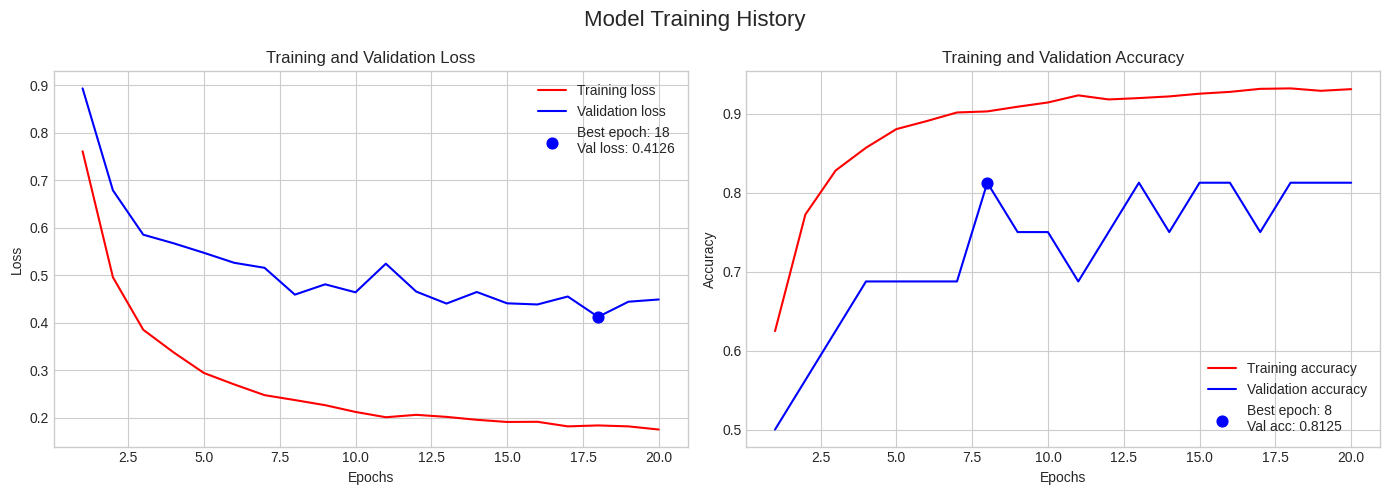

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# Giả định bạn đã có biến history:
# hist = history.history

# Nếu bạn dùng tên khác như history_resnet:
hist = history.history

# Tìm epoch tốt nhất theo val_loss và val_accuracy
best_val_loss_epoch = np.argmin(hist['val_loss'])
best_val_loss = hist['val_loss'][best_val_loss_epoch]

best_val_acc_epoch = np.argmax(hist['val_accuracy'])
best_val_acc = hist['val_accuracy'][best_val_acc_epoch]

epochs = range(1, len(hist['loss']) + 1)

plt.figure(figsize=(14, 5))
plt.suptitle("Model Training History", fontsize=16)

# --- Loss ---
plt.subplot(1, 2, 1)
plt.plot(epochs, hist['loss'], 'r', label='Training loss')
plt.plot(epochs, hist['val_loss'], 'b', label='Validation loss')
plt.scatter(best_val_loss_epoch + 1, best_val_loss, color='blue', s=60,
            label=f'Best epoch: {best_val_loss_epoch + 1}\nVal loss: {best_val_loss:.4f}')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# --- Accuracy ---
plt.subplot(1, 2, 2)
plt.plot(epochs, hist['accuracy'], 'r', label='Training accuracy')
plt.plot(epochs, hist['val_accuracy'], 'b', label='Validation accuracy')
plt.scatter(best_val_acc_epoch + 1, best_val_acc, color='blue', s=60,
            label=f'Best epoch: {best_val_acc_epoch + 1}\nVal acc: {best_val_acc:.4f}')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [44]:
test_loss_ft, test_acc_ft = model.evaluate(test_generator)
print(f"Test Loss after fine-tuning: {test_loss_ft:.4f}, Test Accuracy after fine-tuning: {test_acc_ft:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 272ms/step - accuracy: 0.8345 - loss: 0.5370
Test Loss after fine-tuning: 0.3379, Test Accuracy after fine-tuning: 0.8974


1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step


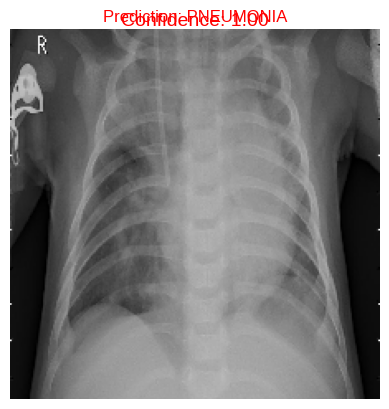

In [48]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model

# 1. Load model
model = load_model('/kaggle/working/resnet152v2_pneumonia_best.h5')  # hoặc 'resnet152v2_pneumonia_best.h5'

def display_prediction(img_path, model, img_size=(224, 224), threshold=0.5):
    from tensorflow.keras.preprocessing import image
    import matplotlib.pyplot as plt
    import numpy as np

    img = image.load_img(img_path, target_size=img_size)
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array)[0][0]
    label = "PNEUMONIA" if prediction > threshold else "NORMAL"
    color = "red" if prediction > threshold else "green"
    conf_text = f"Confidence: {prediction:.2f}"

    plt.imshow(img)
    plt.title(f"Prediction: {label}", color=color)
    plt.axis('off')
    plt.text(0.5, 1.00, conf_text,
             fontsize=14,
             color=color, ha='center', va='bottom',
             transform=plt.gca().transAxes)
    plt.show()


# --- Demo sử dụng ---
if __name__ == "__main__":
    test_img = "/kaggle/input/chest-xray-pneumonia/chest_xray/test/PNEUMONIA/person100_bacteria_481.jpeg"
    display_prediction(test_img, model)


1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
Predicted: PNEUMONIA (100.0%)


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

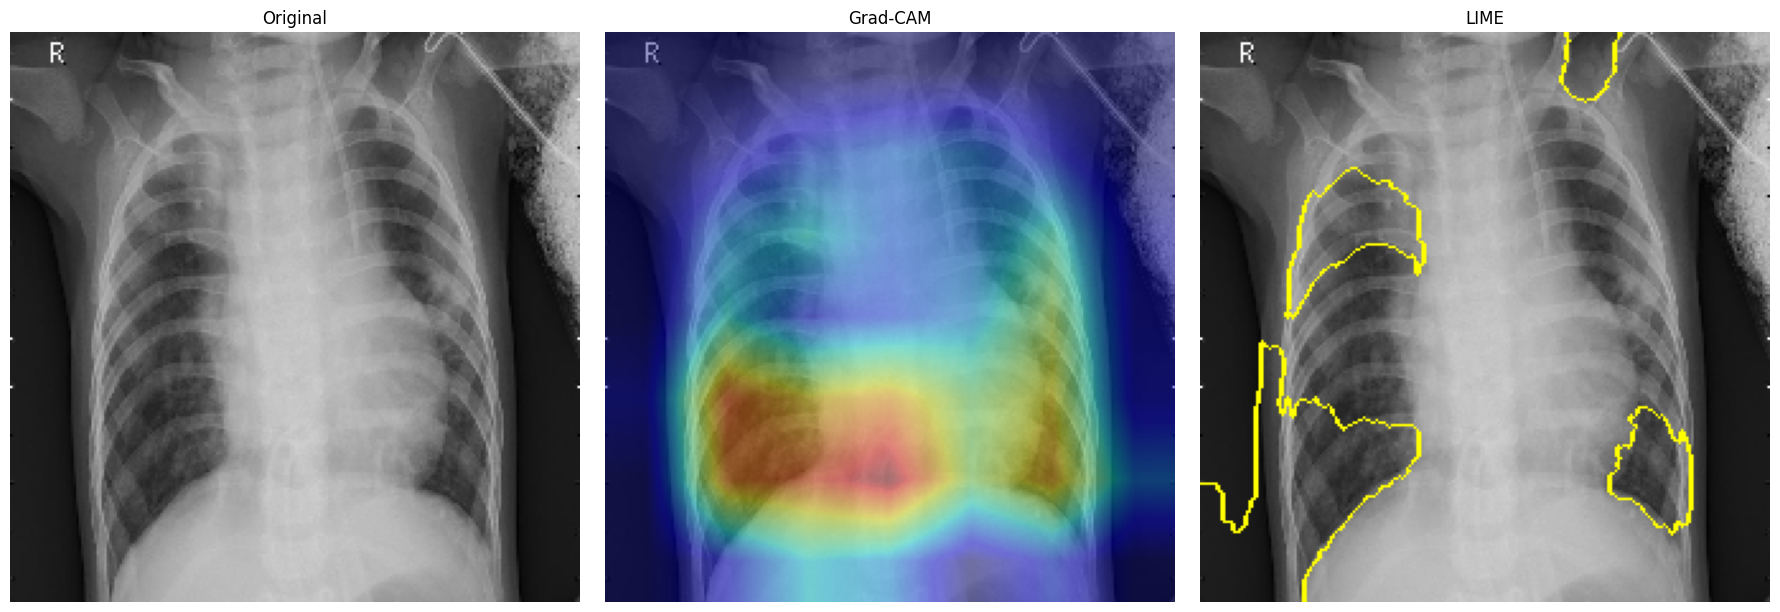

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet_v2 import preprocess_input
from lime import lime_image
from skimage.segmentation import mark_boundaries
import tensorflow as tf
from skimage.color import label2rgb

# ========== 1. Load model ==========
model = load_model('/kaggle/input/resnet152v2/resnet152v2_pneumonia_best.h5')

# Lấy layer convolutional cuối cùng (kiểm tra tên trong model.summary())
last_conv = model.get_layer('conv5_block3_3_conv')

# Khởi tạo grad_model đúng cách
grad_model = Model(inputs=model.input, 
                   outputs=[last_conv.output, model.output])

# ========== 2. Hàm load + tiền xử lý ảnh ==========
def load_and_prep(img_path, target_size=(224,224)):
    img = image.load_img(img_path, target_size=target_size, color_mode='rgb')
    x   = image.img_to_array(img)
    x   = preprocess_input(x)
    return img, np.expand_dims(x, 0)

# ========== 3. Grad-CAM ==========
def make_gradcam_heatmap(img_array, grad_model):
    """
    img_array: shape (1,H,W,3)
    grad_model.outputs = [conv_outputs, model_output]
    """
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_array)
        # preds shape = (1,1), gradient theo class "1" (PNEUMONIA)
        class_channel = preds[:, 0]
    # grads shape = conv_outputs.shape
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def overlay_heatmap(img, heatmap, alpha=0.4, cmap='jet'):
    # Resize heatmap về đúng kích thước ảnh
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (img.size[1], img.size[0])
    )
    heatmap_resized = tf.squeeze(heatmap_resized).numpy()

    # Normalize vào [0,1]
    hm_norm = np.clip(heatmap_resized, 0, 1)

    # Áp colormap
    colored = plt.get_cmap(cmap)(hm_norm)[..., :3]  # shape (H,W,3)

    # Chuyển ảnh gốc về grayscale float 0–1
    gray = np.array(img.convert('L'), dtype=np.float32) / 255.0
    gray_rgb = np.stack([gray]*3, axis=-1)

    # Overlay
    overlay = gray_rgb * (1 - alpha) + colored * alpha
    return np.uint8(overlay * 255)

# ========== 4. LIME (unchanged) ==========
CLASS_NAMES = ['NORMAL','PNEUMONIA']
def explain_lime(img_array, model, top_labels=2, num_samples=1000):
    def predict_fn(x):
        p1 = model.predict(preprocess_input(x))
        p0 = 1 - p1
        return np.concatenate([p0, p1], axis=1)
    explainer = lime_image.LimeImageExplainer()
    return explainer.explain_instance(
        image=img_array[0].astype('double'),
        classifier_fn=predict_fn,
        top_labels=top_labels,
        hide_color=0,
        num_samples=num_samples
    )

# ========== 5. Chạy demo ==========
if __name__ == "__main__":
    img_path = '/kaggle/input/chest-xray-pneumonia/chest_xray/test/PNEUMONIA/person103_bacteria_489.jpeg'
    raw_img, x = load_and_prep(img_path)
    
    # Predict
    prob = model.predict(x)[0,0]
    label = int(prob >= 0.5)
    print(f"Predicted: {CLASS_NAMES[label]} ({prob*100:.1f}%)")
    
    # Grad-CAM
    heatmap = make_gradcam_heatmap(x, grad_model)
    cam_img = overlay_heatmap(raw_img, heatmap)
    
    # LIME
    explanation = explain_lime(x, model)
    temp, mask = explanation.get_image_and_mask(
        label=label,
        positive_only=True,
        num_features=5,
        hide_rest=False
    )
    lime_overlay = mark_boundaries(np.array(raw_img)/255.0, mask, color=(1,1,0))
    
    # Hiển thị cả 3
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(raw_img, cmap='gray');    axes[0].set_title('Original');    axes[0].axis('off')
    axes[1].imshow(cam_img);                 axes[1].set_title('Grad-CAM');    axes[1].axis('off')
    axes[2].imshow(lime_overlay);                axes[2].set_title('LIME');        axes[2].axis('off')
    plt.tight_layout()
    plt.show()
